Introduction to EDA
The main objective of this article is to cover the steps involved in Data pre-processing, Feature Engineering, and different stages of Exploratory Data Analysis, which is an essential step in any research analysis. Data pre-processing, Feature Engineering, and EDA are fundamental early steps after data collection. Still, they are not limited to where the data is simply visualized, plotted, and manipulated, without any assumptions, to assess the quality of the data and building models. This article will guide you through data pre-processing, feature engineering, and EDA using Python.


Table of contents
What is Data Pre-processing and Feature Engineering?
Step 1: Import Python Libraries
Step 2: Reading Dataset
Step 3: Data Reduction
Step 4: Feature Engineering
Step 5: Creating Features
Step 6: Data Cleaning/Wrangling
Step 7: EDA Exploratory Data Analysis
Step 8: Statistics Summary
Step 9: EDA Univariate Analysis
Step 10: Data Transformation
Step 12: EDA Bivariate Analysis
Step 13: EDA Multivariate Analysis
Step 14: Impute Missing values

What is Data Pre-processing and Feature Engineering?
In our data-driven processes, we consider refining our raw data. Both data pre-processing and feature engineering play pivotal roles in this endeavor. Data pre-processing encompasses a range of activities, including data integration, analysis, cleaning, transformation, and dimension reduction.
Data pre-processing involves cleaning and preparing raw data to facilitate feature engineering. Meanwhile, feature engineering entails employing various techniques to manipulate the data. This may include adding or removing relevant features, handling missing data, encoding variables, and dealing with categorical variables, among other tasks.
Undoubtedly, feature engineering is a critical task that significantly influences the outcome of a model. It involves crafting new features based on existing data while pre-processing primarily focuses on cleaning and organizing the data.

Let’s look at how to perform EDA using python!

Step 1: Import Python Libraries
The first step involved in ML using python is understanding and playing around with our data using libraries. Here is the link to the dataset.
Import all libraries which are required for our analysis, such as Data Loading, Statistical analysis, Visualizations, Data Transformations, Merge and Joins, etc.
Pandas and Numpy have been used for Data Manipulation and numerical Calculations
Matplotlib and Seaborn have been used for Data visualizations. 


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
from pathlib import Path, WindowsPath, PureWindowsPath
sys.path.append(str(Path.cwd().parent))

#to ignore warnings
import warnings
warnings.filterwarnings('ignore')
from Intelligence import Utils
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

In [32]:
#Step 2: Reading Dataset
# The Pandas library offers a wide range of possibilities for loading data into the pandas DataFrame from files like JSON, .csv, .xlsx, .sql, .pickle, .html, .txt, images etc.
# Most of the data are available in a tabular format of CSV files. It is trendy and easy to access. Using the read_csv() function, data can be converted to a pandas DataFrame.
# In this article, the data to predict Used car price is being used as an example. In this dataset, we are trying to analyze the used car’s price and how EDA focuses on identifying the factors influencing the car price. We have stored the data in the DataFrame data.
abspath = os.path.abspath("")
#print(abspath)
datapath1 = Path(abspath).parent
print(datapath1)
location = datapath1 / 'Data' # type: ignore
print(location)
fileName = 'vehicles2.csv'
dfData:pd.DataFrame = Utils.GetLocalCSVData(fileName, location=location)


c:\Projects\KalAnalysis
c:\Projects\KalAnalysis\Data


In [33]:
#Analyzing the Data
# Before we make any inferences, we listen to our data by examining all variables in the data.
# The main goal of data understanding is to gain general insights about the data, which covers the number of rows and columns, values in the data, datatypes, and Missing values in the dataset.
# shape – shape will display the number of observations(rows) and features(columns) in the dataset

print(f'There are {dfData.shape[0]} observations and {dfData.shape[1]} variables in our dataset')
 
#head() will display the top 5 observations of the dataset
print(dfData.head())

#tail() will display the last 5 observations of the dataset
print(dfData.tail())
#info() helps to understand the data type and information about data, including the number of records in each column, data having null or not null, Data type, the memory usage of the dataset

print(dfData.info())

#data.info() shows the variables Mileage, Engine, Power, Seats, New_Price, and Price have missing values. Numeric variables like Mileage, Power are of datatype as  float64 and int64. Categorical variables like Location, Fuel_Type, Transmission, and Owner Type are of object data type

There are 10070 observations and 26 variables in our dataset
           id                                                url                  region                         region_url  price  year manufacturer model condition cylinders fuel  odometer  \
0  7222695916  https://prescott.craigslist.org/cto/d/prescott...                prescott    https://prescott.craigslist.org   6000   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
1  7218891961  https://fayar.craigslist.org/ctd/d/bentonville...            fayetteville       https://fayar.craigslist.org  11900   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
2  7221797935  https://keys.craigslist.org/cto/d/summerland-k...            florida keys        https://keys.craigslist.org  21000   NaN          NaN   NaN       NaN       NaN  NaN       NaN   
3  7222270760  https://worcester.craigslist.org/cto/d/west-br...  worcester / central MA   https://worcester.craigslist.org   1500   NaN          NaN   NaN       N

In [34]:
print('Check for Duplication')
#nunique() based on several unique values in each column and the data description, we can identify the continuous and categorical columns in the data. Duplicated data can be handled or removed based on further analysis
print(dfData.nunique())

print('Missing Values Calculation')
# isnull() is widely been in all pre-processing steps to identify null values in the data
# In our example, data.isnull().sum() is used to get the number of missing records in each column
print(dfData.isnull().sum())

print('Percentage of missing values in each column')
pct_missing_vals = (dfData.isnull().sum()/(len(dfData)))*100
print(pct_missing_vals)
#The percentage of missing values for the columns New_Price and Price is ~86% and ~17%, respectively.


Check for Duplication
id              10070
url             10070
region             28
region_url         28
price            1796
year               89
manufacturer       38
model            2482
condition           6
cylinders           8
fuel                5
odometer         4962
title_status        6
transmission        3
VIN              3801
drive               3
size                4
type               13
paint_color        12
image_url        6524
description      8508
county              0
state              13
lat              1414
long             1425
posting_date     9862
dtype: int64
Missing Values Calculation
id                  0
url                 0
region              0
region_url          0
price               0
year              115
manufacturer      490
model             130
condition        4671
cylinders        3292
fuel              122
odometer           58
title_status      249
transmission       83
VIN              3168
drive            2912
size          

In [35]:
#Step 3: Data Reduction
# Some columns or variables can be dropped if they do not add value to our analysis.
# In our dataset, the column url and region_url don’t have any predictive power to predict the dependent variable.
print(' Remove url and region_url columns from data')
dfData = dfData.drop(['url'], axis = 1)
dfData = dfData.drop(['region_url'], axis = 1)
print(dfData.info())

 Remove url and region_url columns from data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            10070 non-null  int64  
 1   region        10070 non-null  object 
 2   price         10070 non-null  int64  
 3   year          9955 non-null   float64
 4   manufacturer  9580 non-null   object 
 5   model         9940 non-null   object 
 6   condition     5399 non-null   object 
 7   cylinders     6778 non-null   object 
 8   fuel          9948 non-null   object 
 9   odometer      10012 non-null  float64
 10  title_status  9821 non-null   object 
 11  transmission  9987 non-null   object 
 12  VIN           6902 non-null   object 
 13  drive         7158 non-null   object 
 14  size          2641 non-null   object 
 15  type          8202 non-null   object 
 16  paint_color   8035 non-null   object 
 17  image_url     10043 non-

In [36]:
#We start our Feature Engineering as we need to add some columns required for analysis.
#Step 4: Feature Engineering
# Feature engineering refers to the process of using domain knowledge to select 
# and transform the most relevant variables from raw data when creating a predictive model 
# using machine learning or statistical modeling. 
# The main goal of Feature engineering is to create meaningful data from raw data.
#Step 5: Creating Features
# We will play around with the variables Year and Name in our dataset. 
# If we see the sample data, the column “Year” shows the manufacturing year of the car.
# It would be difficult to find the car’s age if it is in year format as the Age of the car is a contributing factor to Car Price. 
# Introducing a new column, “car_age” to know the age of the car
from datetime import date
date.today().year
dfData['car_age']=date.today().year-dfData['year']
dfData.head()

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date,car_age
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN,NaN
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN,NaN
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN,NaN
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN,NaN
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN,NaN


In [37]:
#Step 6: Data Cleaning/Wrangling
# Some names of the variables are not relevant and not easy to understand. 
# Some data may have data entry errors, and some variables may need data type conversion. 
# We need to fix this issue in the data.
# In the example manufacturer and model are important and should not have multiple names for a single name 
# Check for unique values will help find typos 
print(dfData.manufacturer.unique())
print(dfData.model.unique())

# The county column is supposed to be a string based column but it is shown as float64.
# We need to convert this column to an object or str column
dfData = dfData.astype({"county": 'str'}) 

# The id column does not have to be a numeric as it is not used in calculations
#Chanding it to object
dfData = dfData.astype({"id": 'object'}) 


[nan 'gmc' 'chevrolet' 'toyota' 'ford' 'jeep' 'nissan' 'ram' 'mazda'
 'cadillac' 'honda' 'dodge' 'lexus' 'jaguar' 'buick' 'chrysler' 'volvo'
 'audi' 'infiniti' 'lincoln' 'alfa-romeo' 'subaru' 'acura' 'hyundai'
 'mercedes-benz' 'bmw' 'mitsubishi' 'volkswagen' 'porsche' 'kia' 'rover'
 'ferrari' 'mini' 'pontiac' 'fiat' 'tesla' 'saturn' 'mercury'
 'harley-davidson']
[nan 'sierra 1500 crew cab slt' 'silverado 1500' ... 'ISUZU NPR'
 'compass sport suv 4d' 'silverado 1500 hybrid']


#Below is an example of correcting errors. 
This is useful in situations where the value was supposed to be in a given format but is not
#We don't need below changes in our dataset, but just for reference
# The brand name ‘Isuzu’ ‘ISUZU’ and ‘Mini’ and ‘Land’ looks incorrect. 
#searchfor = ['Isuzu' ,'ISUZU','Mini','Land']
#data[data.Brand.str.contains('|'.join(searchfor))].head(5)
#data["Brand"].replace({"ISUZU": "Isuzu", "Mini": "Mini Cooper","Land":"Land Rover"}, inplace=True)

# We have done the fundamental data analysis, Featuring, and data clean-up. Let’s move to the EDA process 
# Voila!! Our Data is ready to perform EDA.

Step 7: EDA Exploratory Data Analysis
Exploratory Data Analysis refers to the crucial process of performing initial investigations on data to discover patterns to check assumptions with the help of summary statistics and graphical representations.
EDA can be leveraged to check for outliers, patterns, and trends in the given data.
EDA helps to find meaningful patterns in data.
EDA provides in-depth insights into the data sets to solve our business problems.
EDA gives a clue to impute missing values in the dataset 

In [38]:
#Step 8: Statistics Summary
# The information gives a quick and simple description of the data.
# Can include Count, Mean, Standard Deviation, median, mode, minimum value, maximum value, range, standard deviation, etc.
# Statistics summary gives a high-level idea to identify whether the data has any outliers, data entry error, distribution of data such as the data is normally distributed or left/right skewed
# In python, this can be achieved using describe()
# describe() function gives all statistics summary of data
# describe()– Provide a statistics summary of data belonging to numerical datatype such as int, float
print(dfData.describe().T)

# From the statistics summary, we can infer the below findings :
# Years range from 1996- 2019 and has a high in a range which shows used cars contain both latest models and old model cars.
# On average of Kilometers-driven in Used cars are ~58k KM. The range shows a huge difference between min and max as max values show 650000 KM shows the evidence of an outlier. This record can be removed.
# Min value of Mileage shows 0 cars won’t be sold with 0 mileage. This sounds like a data entry issue.
# It looks like Engine and Power have outliers, and the data is right-skewed.
# The average number of seats in a car is 5. car seat is an important feature in price contribution.
# The max price of a used car is 160k which is quite weird, such a high price for used cars. There may be an outlier or data entry issue.
# describe(include=’all’) provides a statistics summary of all data, include object, category etc
print(dfData.describe(include='all').T)



            count           mean           std          min           25%           50%            75%           max
price     10070.0  129511.462165  9.892154e+06     0.000000   9995.000000  19999.000000   29995.000000  9.876543e+08
year       9955.0    2011.927172  9.979647e+00  1903.000000   2010.000000   2015.000000    2018.000000  2.022000e+03
odometer  10012.0  105976.984818  4.581422e+05     0.000000  27775.750000  67800.000000  123728.500000  1.000000e+07
lat        9998.0      43.262747  1.333367e+01   -81.838232     33.455361     34.756558      61.161670  6.499370e+01
long       9998.0    -111.376072  2.894376e+01  -158.599600   -149.847206    -88.105874     -86.653907  1.738855e+02
car_age    9955.0      11.072828  9.979647e+00     1.000000      5.000000      8.000000      13.000000  1.200000e+02
                count   unique                                                top   freq           mean             std        min         25%        50%        75%          max
id 

In [39]:
#Before we do EDA, lets separate Numerical and categorical variables for easy analysis
cat_cols=dfData.select_dtypes(include=['object']).columns
num_cols = dfData.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
Index(['id', 'region', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'county',
       'state', 'posting_date'],
      dtype='object')
Numerical Variables:
['price', 'year', 'odometer', 'lat', 'long', 'car_age']


price
Skew : 98.93


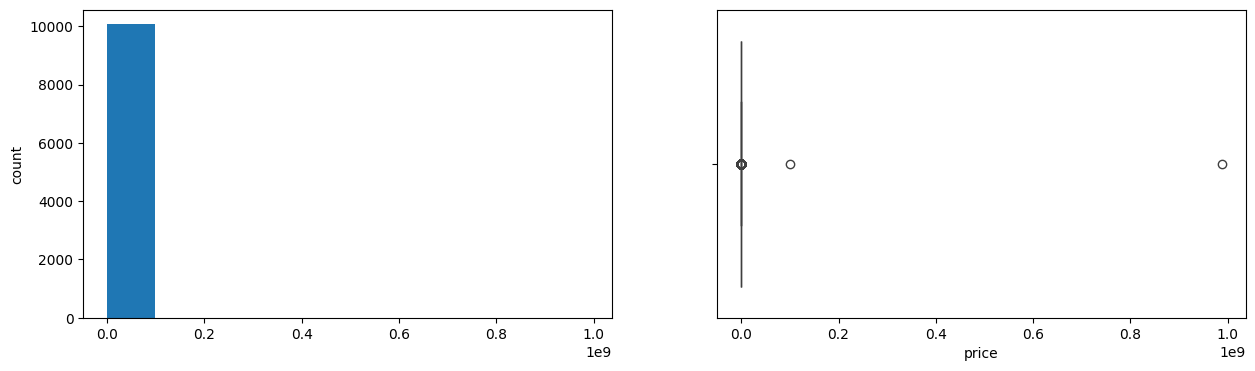

year
Skew : -3.6


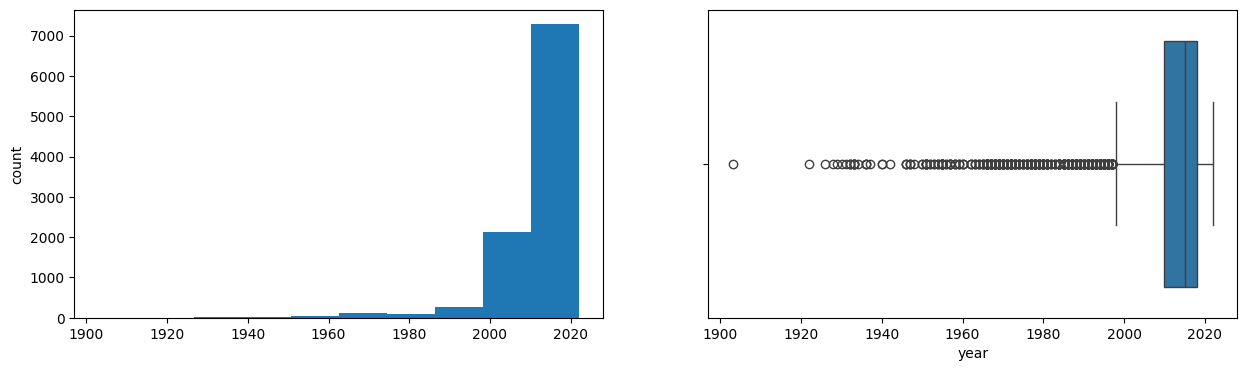

odometer
Skew : 20.57


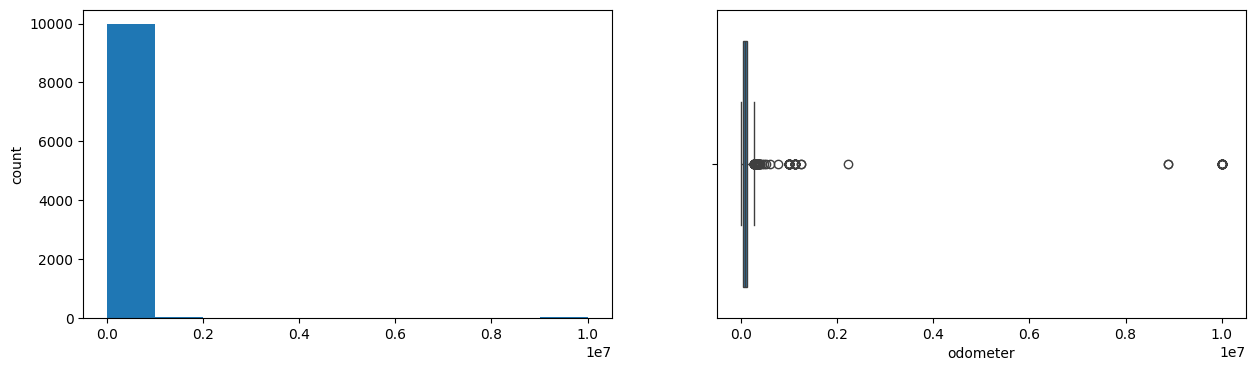

lat
Skew : 0.46


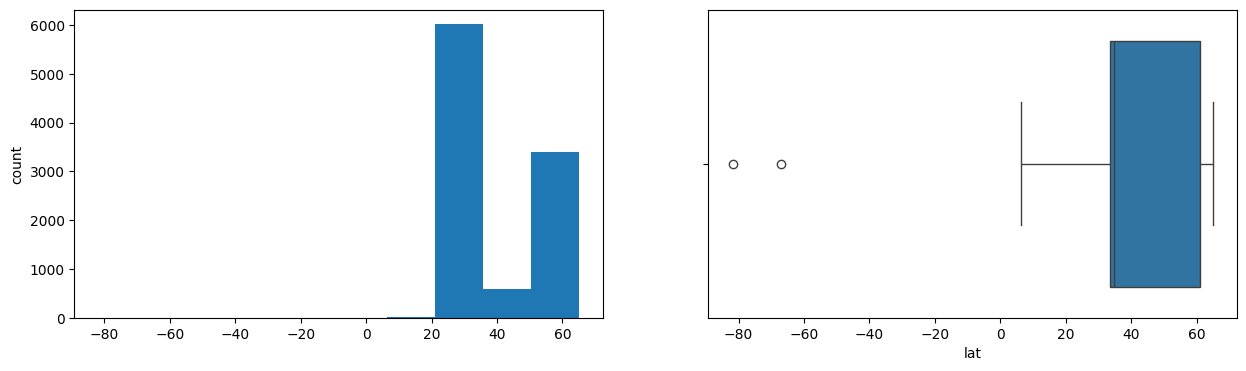

long
Skew : -0.33


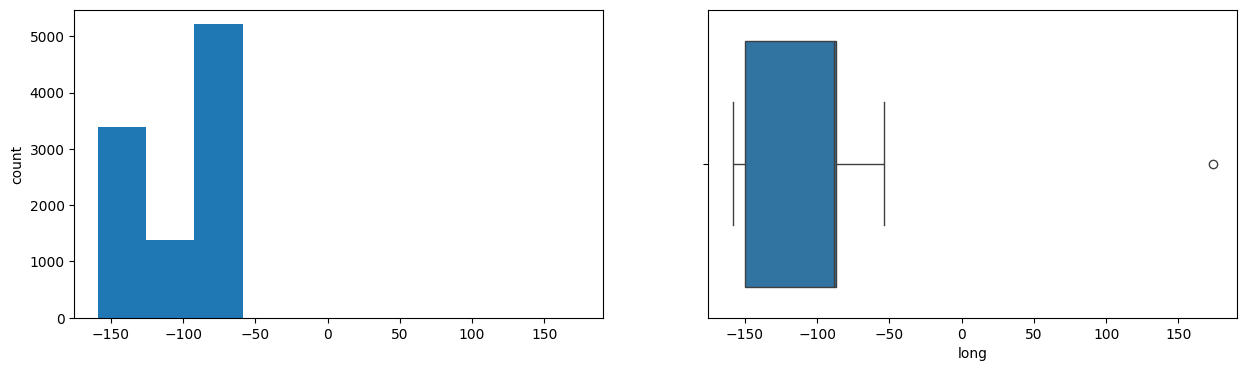

car_age
Skew : 3.6


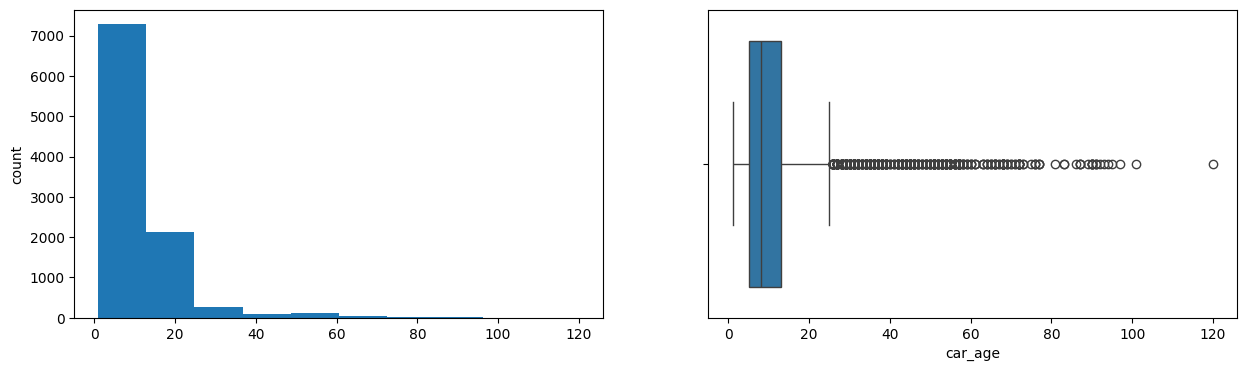

In [40]:
#Step 9: EDA Univariate Analysis
# Analyzing/visualizing the dataset by taking one variable at a time:
# Data visualization is essential; we must decide what charts to plot to better understand the data. In this article, we visualize our data using Matplotlib and Seaborn libraries.
# Matplotlib is a Python 2D plotting library used to draw basic charts we use Matplotlib.
# Seaborn is also a python library built on top of Matplotlib that uses short lines of code to create and style statistical plots from Pandas and Numpy
# Univariate analysis can be done for both Categorical and Numerical variables.
# Categorical variables can be visualized using a Count plot, Bar Chart, Pie Plot, etc.
# Numerical Variables can be visualized using Histogram, Box Plot, Density Plot, etc.
# In our example, we have done a Univariate analysis using Histogram and  Box Plot for continuous Variables.
# In the below fig, a histogram and box plot is used to show the pattern of the variables, as some variables have skewness and outliers.
for col in num_cols:
    print(col)
    print('Skew :', round(dfData[col].skew(), 2))
    plt.figure(figsize = (15, 4))
    plt.subplot(1, 2, 1)
    dfData[col].hist(grid=False)
    plt.ylabel('count')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=dfData[col])
    plt.show()


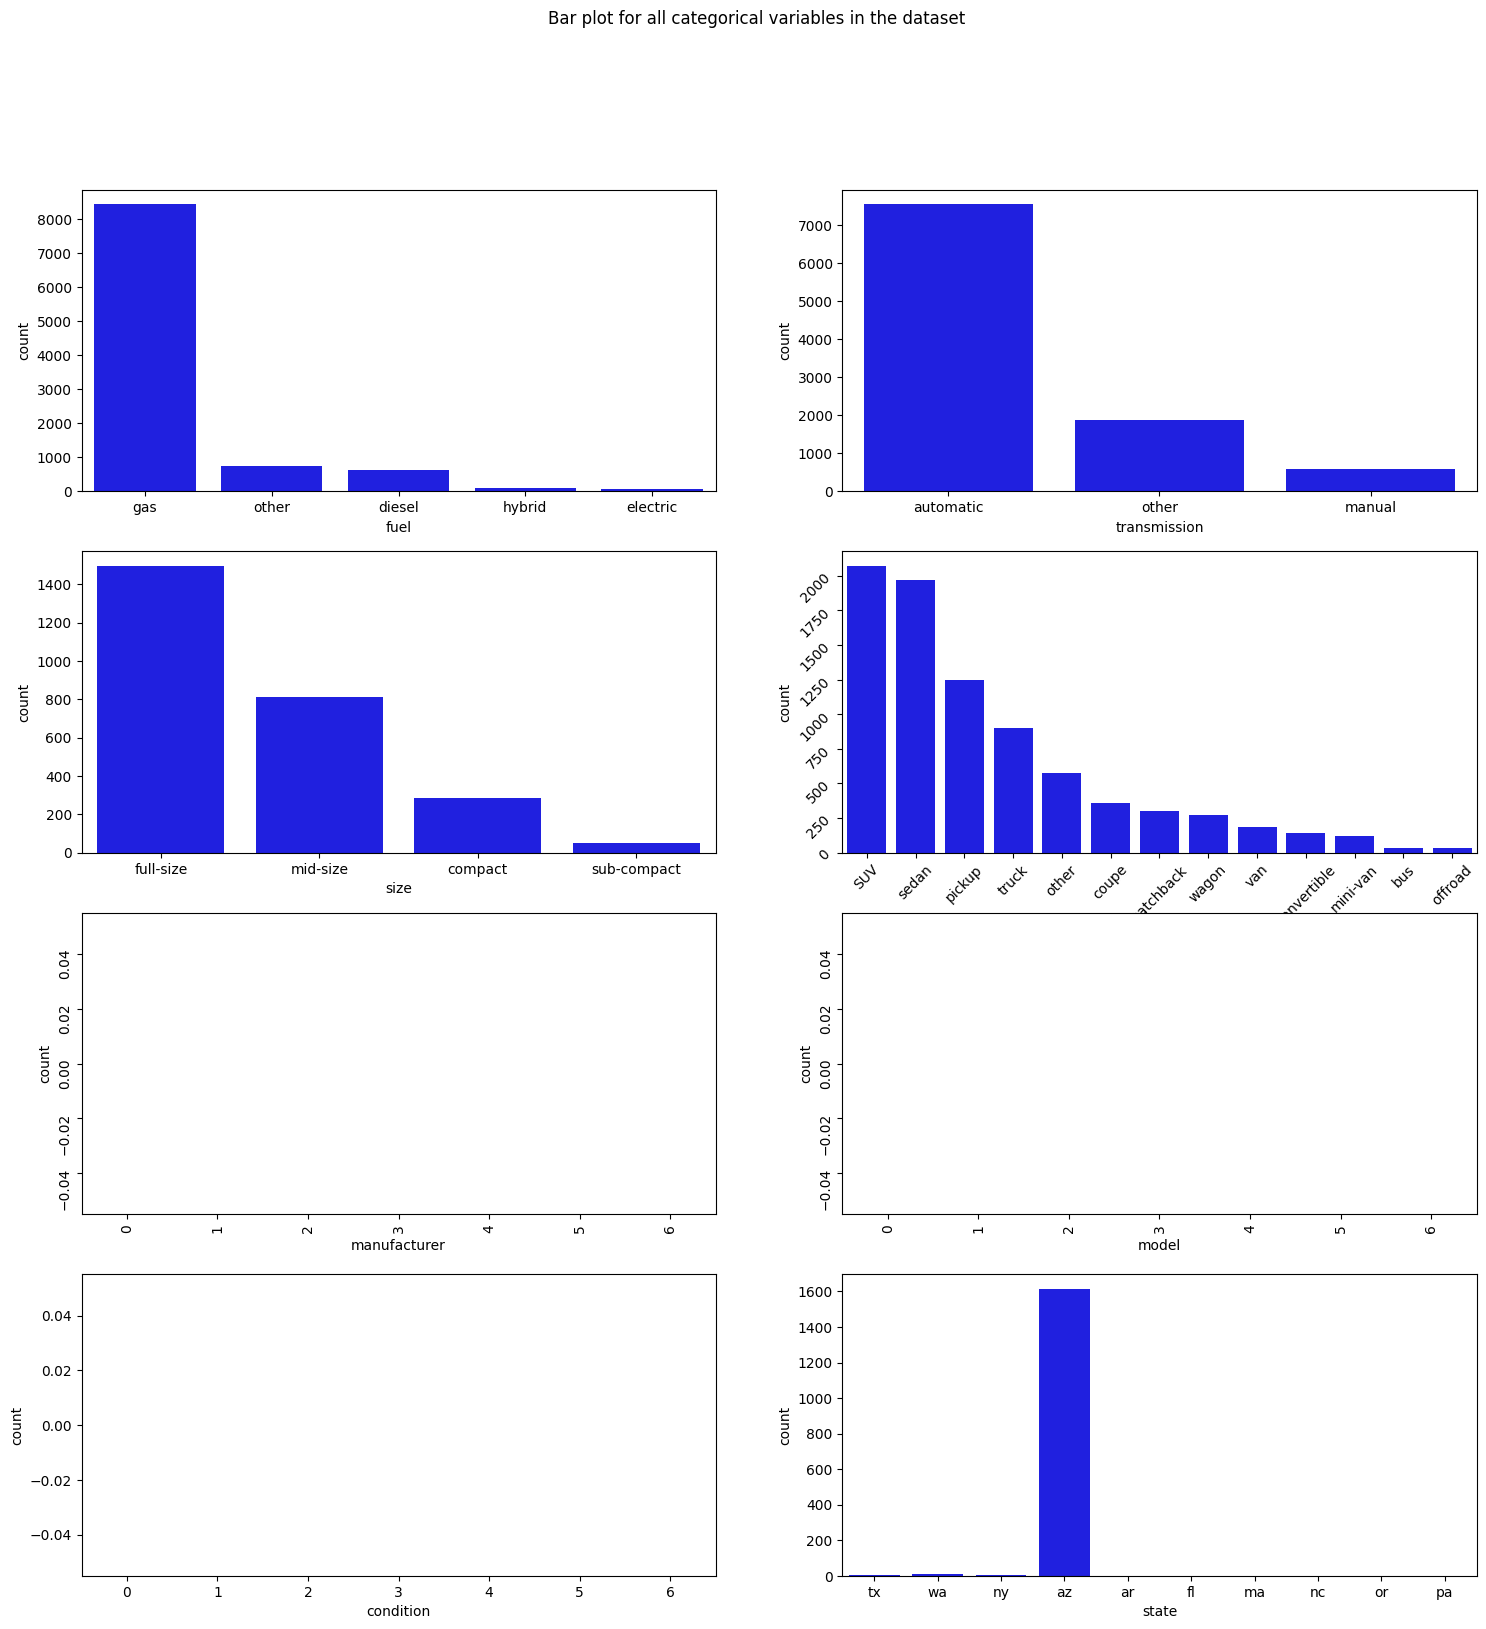

In [41]:
# Price and Kilometers Driven are right skewed for this data to be transformed, 
# and all outliers will be handled during imputation
# categorical variables are being visualized using a count plot. 
# Categorical variables provide the pattern of factors influencing car price
fig, axes = plt.subplots(4, 2, figsize = (18, 18))
fig.suptitle('Bar plot for all categorical variables in the dataset')
sns.countplot(ax = axes[0, 0], x = 'fuel', data = dfData, color = 'blue', 
              order = dfData['fuel'].value_counts().index);
sns.countplot(ax = axes[0, 1], x = 'transmission', data = dfData, color = 'blue', 
              order = dfData['transmission'].value_counts().index);

#sns.countplot(ax = axes[1, 0], x = 'Owner_Type', data = dfData, color = 'blue', 
#order = dfData['Owner_Type'].value_counts().index);

sns.countplot(ax = axes[1, 0], x = 'size', data = dfData, color = 'blue', 
              order = dfData['size'].value_counts().index);
sns.countplot(ax = axes[1, 1], x = 'type', data = dfData, color = 'blue', 
              order = dfData['type'].value_counts().index);
sns.countplot(ax = axes[2, 0], x = 'manufacturer', data = dfData, color = 'blue', 
              order = dfData['manufacturer'].head(20).value_counts().index);
sns.countplot(ax = axes[2, 1], x = 'model', data = dfData, color = 'blue', 
              order = dfData['model'].head(20).value_counts().index);
sns.countplot(ax = axes[3, 0], x = 'condition', data = dfData, color = 'blue', 
              order = dfData['condition'].head(20).value_counts().index);
sns.countplot(ax = axes[3, 1], x = 'state', data = dfData, color = 'blue', 
              order = dfData['state'].head(20).value_counts().index);
axes[1][1].tick_params(labelrotation=45);
axes[2][0].tick_params(labelrotation=90);
axes[2][1].tick_params(labelrotation=90);

# From the count plot, we can have below observations
# Gas fuel cars outnumber all the other fuel types. They are more popular than all the other fuel types combined
# SUVs and Sedans are the most popular followed closely by Trucks
# Most cars have automatic transmission


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 27 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            10070 non-null  object 
 1   region        10070 non-null  object 
 2   price         10070 non-null  int64  
 3   year          9955 non-null   float64
 4   manufacturer  9580 non-null   object 
 5   model         9940 non-null   object 
 6   condition     5399 non-null   object 
 7   cylinders     6778 non-null   object 
 8   fuel          9948 non-null   object 
 9   odometer      10012 non-null  float64
 10  title_status  9821 non-null   object 
 11  transmission  9987 non-null   object 
 12  VIN           6902 non-null   object 
 13  drive         7158 non-null   object 
 14  size          2641 non-null   object 
 15  type          8202 non-null   object 
 16  paint_color   8035 non-null   object 
 17  image_url     10043 non-null  object 
 18  description   10043 non-nu

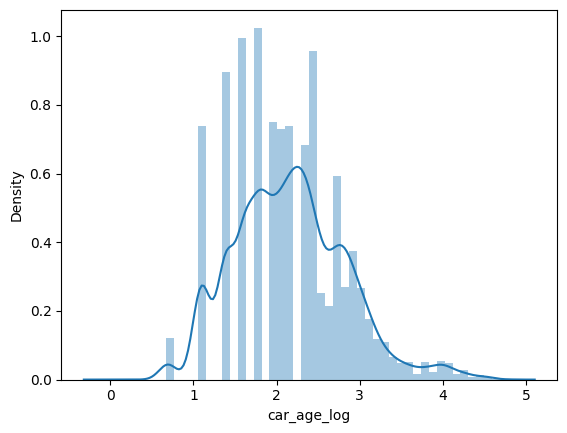

In [42]:
#Step 10: Data Transformation
# Before we proceed to Bi-variate Analysis, Univariate analysis demonstrated the data pattern as some variables to be transformed.
# Price and Kilometer-Driven variables are highly skewed and on a larger scale. Let’s do log transformation.
# Log transformation can help in normalization, so this variable can maintain standard scale with other variables:
# Function for log transformation of the column
def log_transform(dfLog, col):
    for colname in col:
        if (dfLog[colname] == 1.0).all():
            dfLog[colname + '_log'] = np.log(dfLog[colname]+1)
        else:
            dfLog[colname + '_log'] = np.log(dfLog[colname])
    dfLog.info()
log_transform(dfData,['car_age','price'])
sns.distplot(dfData["car_age_log"], axlabel="car_age_log");


In [43]:
#Step 12: EDA Bivariate Analysis
# Now, let’s move ahead with bivariate analysis. Bivariate Analysis helps to understand how variables are related 
# to each other and the relationship between dependent and independent variables present in the dataset.
# For Numerical variables, Pair plots and Scatter plots are widely been used to do Bivariate Analysis.
# A Stacked bar chart can be used for categorical variables if the output variable is a classifier. 
# Bar plots can be used if the output variable is continuous
# In our example, a pair plot has been used to show the relationship between two Categorical variables.
#pair_plot_cols = ['type', 'size', 'manufacturer', 'price']

#pair_plot_cols = ['type', 'price']
#plt.figure(figsize=(13,17))
#sns.pairplot(data=dfData, vars=pair_plot_cols)
#plt.show()

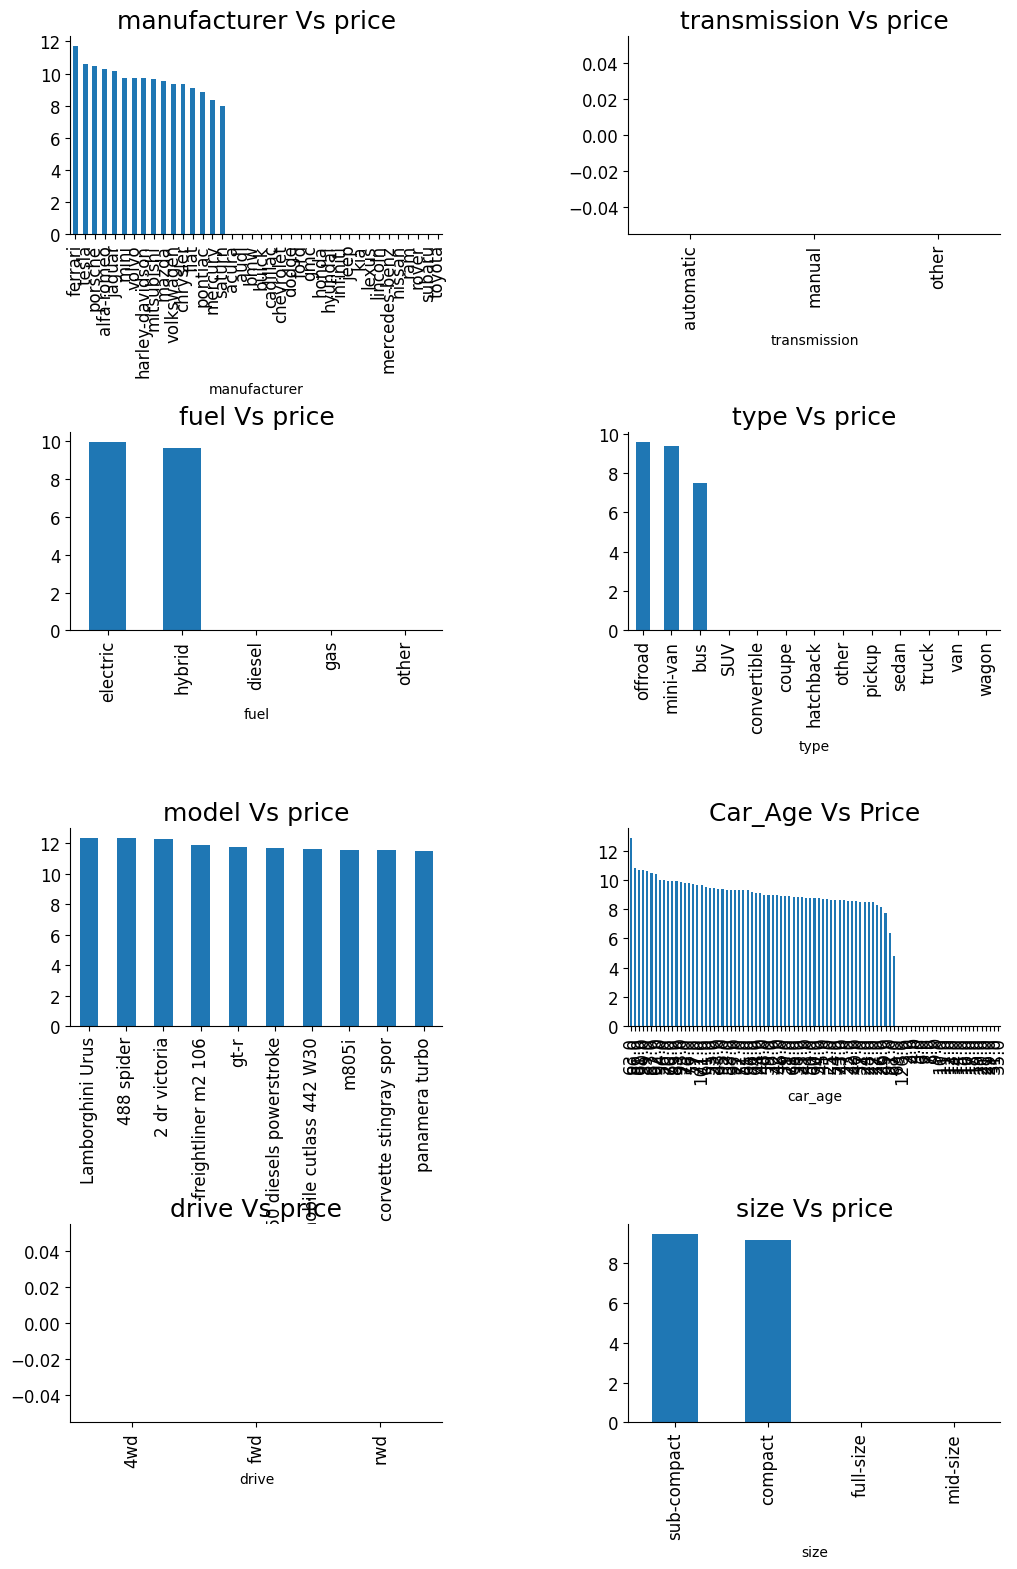

In [44]:
# Pair Plot provides below insights:
# The variable Year has a positive correlation with price and mileage
# A year has a Negative correlation with kilometers-Driven
# Mileage is negatively correlated with Power
# As power increases, mileage decreases
# Car with recent make is higher at prices. As the age of the car increases price decreases
# Engine and Power increase, and the price of the car increases
# A bar plot can be used to show the relationship between Categorical variables and continuous variables 
fig, axarr = plt.subplots(4, 2, figsize=(12, 18))
dfData.groupby('manufacturer')['price_log'].mean().sort_values(ascending=False).plot.bar(ax=axarr[0][0], fontsize=12)
axarr[0][0].set_title("manufacturer Vs price", fontsize=18)
dfData.groupby('transmission')['price_log'].mean().sort_values(ascending=False).plot.bar(ax=axarr[0][1], fontsize=12)
axarr[0][1].set_title("transmission Vs price", fontsize=18)
dfData.groupby('fuel')['price_log'].mean().sort_values(ascending=False).plot.bar(ax=axarr[1][0], fontsize=12)
axarr[1][0].set_title("fuel Vs price", fontsize=18)
dfData.groupby('type')['price_log'].mean().sort_values(ascending=False).plot.bar(ax=axarr[1][1], fontsize=12)
axarr[1][1].set_title("type Vs price", fontsize=18)
dfData.groupby('model')['price_log'].mean().sort_values(ascending=False).head(10).plot.bar(ax=axarr[2][0], fontsize=12)
axarr[2][0].set_title("model Vs price", fontsize=18)
dfData.groupby('car_age')['price_log'].mean().sort_values(ascending=False).plot.bar(ax=axarr[2][1], fontsize=12)
axarr[2][1].set_title("Car_Age Vs Price", fontsize=18)
dfData.groupby('drive')['price_log'].mean().sort_values(ascending=False).head(10).plot.bar(ax=axarr[3][0], fontsize=12)
axarr[3][0].set_title("drive Vs price", fontsize=18)
dfData.groupby('size')['price_log'].mean().sort_values(ascending=False).plot.bar(ax=axarr[3][1], fontsize=12)
axarr[3][1].set_title("size Vs price", fontsize=18)
plt.subplots_adjust(hspace=1.0)
plt.subplots_adjust(wspace=.5)
sns.despine()


Observations
The price of cars is high in Coimbatore and less price in Kolkata and Jaipur
Automatic cars have more price than manual cars.
Diesel and Electric cars have almost the same price, which is maximum, and LPG cars have the lowest price
First-owner cars are higher in price, followed by a second
The third owner’s price is lesser than the Fourth and above
Lamborghini brand is the highest in price
Gallardocoupe Model is the highest in price
2 Seater has the highest price followed by 7 Seater
The latest model cars are high in price

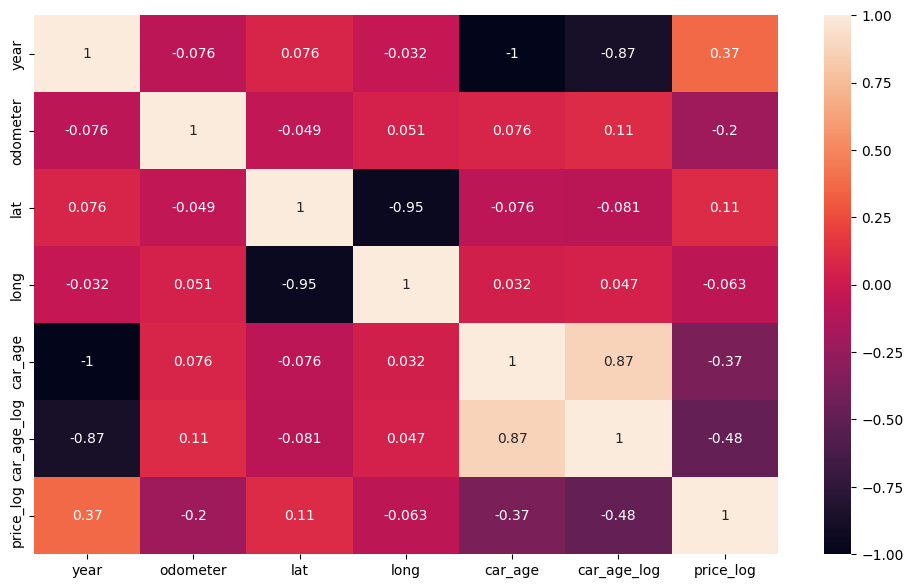

In [45]:
#Step 13: EDA Multivariate Analysis
# As the name suggests, Multivariate analysis looks at more than two variables. Multivariate analysis is one of the most useful methods to determine relationships and analyze patterns for any dataset.
# A heat map is widely been used for Multivariate Analysis
# Heat Map gives the correlation between the variables, whether it has a positive or negative correlation.
# In our example heat map shows the correlation between the variables.
plt.figure(figsize=(12, 7))
sns.heatmap(dfData.drop(['fuel','price'],axis=1).corr(), annot = True, vmin = -1, vmax = 1)
plt.show()

# From the Heat map, we can infer the following:
# The engine has a strong positive correlation to Power 0.86
# Price has a positive correlation to Engine 0.69 as well Power 0.77
# Mileage has correlated to Engine, Power, and Price negatively
# Price is moderately positive in correlation to year.
# Kilometer driven has a negative correlation to year not much impact on the price
# Car age has a negative correlation with Price
# car Age is positively correlated to Kilometers-Driven as the Age of the car increases; then the kilometer will also increase of car has a negative correlation with Mileage this makes sense


In [46]:
#Step 14: Impute Missing values
# Missing data arise in almost all statistical analyses. There are many ways to impute missing values; we can impute the missing values by their Mean, median, most frequent, or zero values and use advanced imputation algorithms like KNN, Regularization, etc.
# We cannot impute the data with a simple Mean/Median. We must need business knowledge or common insights about the data. If we have domain knowledge, it will add value to the imputation. Some data can be imputed on assumptions.
# In our dataset, we have found there are missing values for many columns like Mileage, Power, and Seats.
# We observed earlier some observations have zero Mileage. This looks like a data entry issue. 
# We could fix this by filling null values with zero and then the mean value of Mileage 
# since Mean and Median values are nearly the same for this variable chosen Mean to impute the values.
dfData.loc[dfData["Mileage"]==0.0,'Mileage']=np.nan
dfData.Mileage.isnull().sum()
dfData['Mileage'].fillna(value=np.mean(dfData['Mileage']),inplace=True)
# Similarly, imputation for Seats. As we mentioned earlier, we need to know common insights about the data.
# Let’s assume some cars brand and Models have features like Engine, Mileage, Power, and Number of seats that are nearly the same. Let’s impute those missing values with the existing data:
dfData.Seats.isnull().sum()
dfData['Seats'].fillna(value=np.nan,inplace=True)
dfData['Seats']=dfData.groupby(['Model','Brand'])['Seats'].apply(lambda x:x.fillna(x.median()))
dfData['Engine']=dfData.groupby(['Brand','Model'])['Engine'].apply(lambda x:x.fillna(x.median()))
dfData['Power']=dfData.groupby(['Brand','Model'])['Power'].apply(lambda x:x.fillna(x.median()))
#In general, there are no defined or perfect rules for imputing missing values in a dataset. 
# Each method can perform better for some datasets but may perform even worse. 
# Only practice and experiments give the knowledge which works better.


KeyError: 'Mileage'

Conclusion
In this article, we tried to analyze the factors influencing the used car’s price.
Data Analysis helps to find the basic structure of the dataset.
Dropped columns that are not adding value to our analysis.
Performed Feature Engineering by adding some columns which contribute to our analysis.
Data Transformations have been used to normalize the columns.
We used different visualizations for EDA like Univariate, Bi-Variate, and Multivariate Analysis.
Through EDA, we got useful insights, and below are the factors influencing the price of the car and a few takeaways:
Most of the customers prefer 2 Seat cars hence the price of the 2-seat cars is higher than other cars.
The price of the car decreases as the Age of the car increases.
Customers prefer to purchase the First owner rather than the Second or Third.
Due to increased Fuel price, the customer prefers to purchase an Electric vehicle.
Automatic Transmission is easier than Manual.
This way, we perform EDA on the datasets to explore the data and extract all possible insights, which can help in model building and better decision making.
However, this was only an overview of how EDA works; you can go deeper into it and attempt the stages on larger datasets.
If the EDA process is clear and precise, our model will work better and gives higher accuracy!


Frequently Asked Question
Q1. What is EDA with Python?
A. Exploratory Data Analysis (EDA) with Python involves analyzing and summarizing data to gain insights and understand its underlying patterns, relationships, and distributions using Python programming language.
Q2. How to make EDA in Python?
A. To perform EDA in Python, you can use libraries like Pandas, NumPy, Matplotlib, and Seaborn. These libraries provide functions and tools for data manipulation, visualization, and statistical analysis, which facilitate the process of exploring and understanding the data.
Q3. Which is the best EDA tool Python?
A. The choice of the best EDA tool in Python depends on your specific requirements and preferences. Some popular EDA tools include Jupyter Notebook (with the aforementioned libraries), Plotly, Tableau, and Power BI. Each tool offers unique features and capabilities, so it’s advisable to explore them and choose the one that suits your needs best.
Q4. How to perform EDA in machine learning?
A. Performing EDA in machine learning typically involves preprocessing the data by handling missing values, outliers, and feature scaling. Then, various statistical and visual techniques can be employed to analyze the relationships between variables, identify patterns, and assess the relevance of features. This helps in gaining a better understanding of the data before building a machine learning model.
